# Actividad 4 — Evaluación de tres modelos preentrenados de Hugging Face


In [1]:
%pip uninstall -y hf-gradio gradio gradio_client diffusers
%pip install -q "transformers>=4.44,<5" "datasets>=3,<5" "accelerate>=1,<2" "scikit-learn>=1.3,<2" "huggingface-hub>=0.34,<1" "jedi>=0.19,<1" pandas matplotlib scipy
%pip check


Found existing installation: hf-gradio 0.4.1
Uninstalling hf-gradio-0.4.1:
  Successfully uninstalled hf-gradio-0.4.1
Found existing installation: gradio 6.29.0
Uninstalling gradio-6.29.0:
  Successfully uninstalled gradio-6.29.0
Found existing installation: gradio_client 2.7.1
Uninstalling gradio_client-2.7.1:
  Successfully uninstalled gradio_client-2.7.1
Found existing installation: diffusers 0.40.0
Uninstalling diffusers-0.40.0:
  Successfully uninstalled diffusers-0.40.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 57.0 MB/s eta 0:00:00
No broken requirements found.


In [2]:
import os, time, json, random, platform
import numpy as np, pandas as pd, torch
from pathlib import Path
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
import matplotlib.pyplot as plt
from huggingface_hub import login
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'No disponible')
try:
    from google.colab import userdata
    token=userdata.get('HF_TOKEN')
    if token: login(token=token, add_to_git_credential=False)
except (ImportError, KeyError, Exception) as e:
    print('Autenticación opcional omitida:', type(e).__name__)
Path('results').mkdir(exist_ok=True); Path('data').mkdir(exist_ok=True)

Dispositivo: cuda | GPU: Tesla T4
Autenticación opcional omitida: SecretNotFoundError


In [3]:
dataset=load_dataset('glue','sst2',split='validation')
frame=dataset.to_pandas()[['sentence','label','idx']].rename(columns={'sentence':'text','label':'label','idx':'source_id'})
print('Dataset original:',frame.shape, '\nClases:',frame.label.value_counts().to_dict())
N_PER_CLASS=100
sample=(frame.groupby('label',group_keys=False).sample(n=min(N_PER_CLASS,frame.label.value_counts().min()),random_state=SEED).sort_values('source_id').reset_index(drop=True))
assert sample.label.nunique()==2 and not sample.text.isna().any()
sample.to_csv('data/sst2_validation_sample.csv',index=False)
print('Muestra:',sample.shape,'\n',sample.label.value_counts().to_dict())
sample.head()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

sst2/train-00000-of-00001.parquet:   0%|          | 0.00/3.11M [00:00<?, ?B/s]

sst2/validation-00000-of-00001.parquet:   0%|          | 0.00/72.8k [00:00<?, ?B/s]

sst2/test-00000-of-00001.parquet:   0%|          | 0.00/148k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

Dataset original: (872, 3) 
Clases: {1: 444, 0: 428}
Muestra: (200, 3) 
 {0: 100, 1: 100}


,text,label,source_id
0,unflinchingly bleak and desperate,0,1
1,allows us to hope that nolan is poised to emba...,1,2
2,it takes a strange kind of laziness to waste t...,0,11
3,"in its best moments , resembles a bad high sch...",0,19
4,"it 's a cookie-cutter movie , a cut-and-paste ...",0,28


In [4]:
MODELS={
 'DistilBERT':'distilbert/distilbert-base-uncased-finetuned-sst-2-english',
 'BERT':'textattack/bert-base-uncased-SST-2',
 'RoBERTa':'textattack/roberta-base-SST-2'
}
BATCH_SIZE=16
MAX_LENGTH=128
records=[]; predictions={}; timings={}; model_details={}
for name,model_id in MODELS.items():
    print('Evaluando:',name,model_id)
    tokenizer=AutoTokenizer.from_pretrained(model_id)
    model=AutoModelForSequenceClassification.from_pretrained(model_id).to(DEVICE).eval()
    # validar semántica de etiquetas en vez de asumir índices
    print('Mapeo:',model.config.id2label)
    model_details[name]={'model_id':model_id,'revision':getattr(model.config,'_commit_hash',None),'id2label':model.config.id2label}
    label_names={int(k):str(v).upper() for k,v in model.config.id2label.items()}
    assert len(label_names)==2, 'Se espera un clasificador binario'
    def to_binary(i):
        v=label_names[int(i)]
        if 'NEG' in v or v=='LABEL_0':return 0
        if 'POS' in v or v=='LABEL_1':return 1
        raise ValueError(f'Etiqueta no reconocida: {v}')
    texts=sample.text.tolist()
    with torch.inference_mode():
        warm=tokenizer(texts[:min(4,len(texts))],return_tensors='pt',padding=True,truncation=True,max_length=MAX_LENGTH).to(DEVICE)
        _=model(**warm)
        if DEVICE=='cuda':torch.cuda.synchronize()
        t0=time.perf_counter(); pred=[]
        for j in range(0,len(texts),BATCH_SIZE):
            batch=tokenizer(texts[j:j+BATCH_SIZE],return_tensors='pt',padding=True,truncation=True,max_length=MAX_LENGTH).to(DEVICE)
            logits=model(**batch).logits
            pred.extend(to_binary(k) for k in logits.argmax(dim=-1).cpu().tolist())
        if DEVICE=='cuda':torch.cuda.synchronize()
        elapsed=time.perf_counter()-t0
        # Repeticiones adicionales para latencia; mismas entradas y tamaño de lote
        measured=[elapsed]
        for repeat in range(4):
            if DEVICE=='cuda':torch.cuda.synchronize()
            t_rep=time.perf_counter()
            for j in range(0,len(texts),BATCH_SIZE):
                batch=tokenizer(texts[j:j+BATCH_SIZE],return_tensors='pt',padding=True,truncation=True,max_length=MAX_LENGTH).to(DEVICE)
                _=model(**batch).logits
            if DEVICE=='cuda':torch.cuda.synchronize()
            measured.append(time.perf_counter()-t_rep)
        timings[name]=[t/len(texts)*1000 for t in measured]
        elapsed=float(np.median(measured))
    y=sample.label.to_numpy()
    precision,recall,f1,_=precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    nparams=sum(p.numel() for p in model.parameters())
    records.append(dict(model=name,model_id=model_id,accuracy=accuracy_score(y,pred),precision_macro=precision,recall_macro=recall,f1_macro=f1,latency_ms_per_text=elapsed/len(texts)*1000,throughput_texts_s=len(texts)/elapsed,parameters_million=nparams/1e6,device=DEVICE,n=len(texts)))
    predictions[name]=pred
    print(classification_report(y,pred,zero_division=0))
    del model,tokenizer
    if DEVICE=='cuda':torch.cuda.empty_cache()
results=pd.DataFrame(records).sort_values('f1_macro',ascending=False)
results.to_csv('results/metrics.csv',index=False)
pd.DataFrame({'source_id':sample.source_id,'label':sample.label,**predictions}).to_csv('results/predictions.csv',index=False)
results

Evaluando: DistilBERT distilbert/distilbert-base-uncased-finetuned-sst-2-english


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

Some weights of the model checkpoint at textattack/roberta-base-SST-2 were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Mapeo: {0: 'LABEL_0', 1: 'LABEL_1'}
              precision    recall  f1-score   support

           0       0.90      0.95      0.93       100
           1       0.95      0.90      0.92       100

    accuracy                           0.93       200
   macro avg       0.93      0.93      0.92       200
weighted avg       0.93      0.93      0.92       200



,model,model_id,accuracy,precision_macro,recall_macro,f1_macro,latency_ms_per_text,throughput_texts_s,parameters_million,device,n
2,RoBERTa,textattack/roberta-base-SST-2,0.925,0.926065,0.925,0.924953,2.974148,336.230755,124.647170,cuda,200
1,BERT,textattack/bert-base-uncased-SST-2,0.920,0.920168,0.920,0.919992,4.069889,245.706967,109.483778,cuda,200
0,DistilBERT,distilbert/distilbert-base-uncased-finetuned-s...,0.875,0.875940,0.875,0.874922,1.457107,686.291593,66.955010,cuda,200


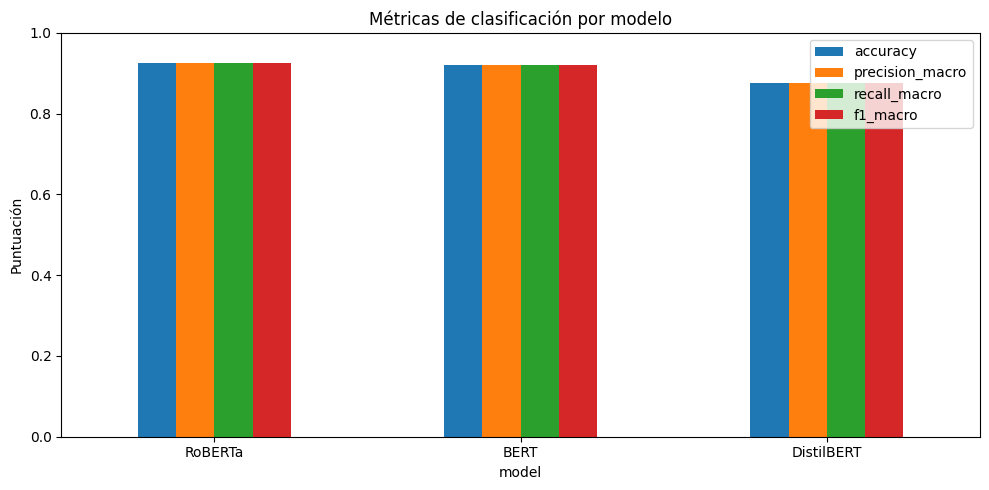

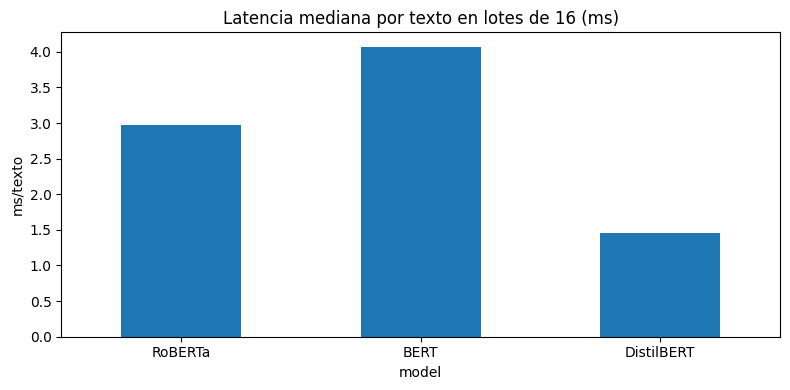

DistilBERT 
 [[85 15]
 [10 90]]
BERT 
 [[91  9]
 [ 7 93]]
RoBERTa 
 [[95  5]
 [10 90]]
RECOMENDACIÓN: RoBERTa Cumple umbrales académicos y equilibra F1 y latencia.


In [5]:
ax=results.set_index('model')[['accuracy','precision_macro','recall_macro','f1_macro']].plot.bar(figsize=(10,5),ylim=(0,1),rot=0)
ax.set_title('Métricas de clasificación por modelo');ax.set_ylabel('Puntuación');plt.tight_layout();plt.savefig('results/comparison.png',dpi=160);plt.show()
ax=results.set_index('model')['latency_ms_per_text'].plot.bar(figsize=(8,4),rot=0)
ax.set_title('Latencia mediana por texto en lotes de 16 (ms)');ax.set_ylabel('ms/texto');plt.tight_layout();plt.savefig('results/latency.png',dpi=160);plt.show()
for name,pred in predictions.items():
    print(name,'\n',confusion_matrix(sample.label,pred,labels=[0,1]))
eligible=results[(results.f1_macro>=0.85)&(results.latency_ms_per_text<=100)]
if len(eligible):
    best_f1=eligible.f1_macro.max()
    recommended=eligible[eligible.f1_macro>=best_f1-0.01].sort_values('latency_ms_per_text').iloc[0]
    rationale='Cumple umbrales académicos y equilibra F1 y latencia.'
else:
    recommended=results.iloc[0]
    rationale='Ningún modelo cumple ambos umbrales; se selecciona mayor F1 para revisión, no despliegue.'
print('RECOMENDACIÓN:',recommended['model'],rationale)
metadata={'seed':SEED,'device':DEVICE,'gpu':torch.cuda.get_device_name(0) if DEVICE=='cuda' else None,'python':platform.python_version(),'torch':torch.__version__,'sample_per_class':N_PER_CLASS,'batch_size':BATCH_SIZE,'max_length':MAX_LENGTH,'recommendation':recommended['model'],'rationale':rationale}
with open('results/run_metadata.json','w') as f:json.dump(metadata,f,indent=2)

In [6]:
from scipy.stats import norm
from sklearn.metrics import f1_score
from importlib.metadata import version

def wilson_interval(successes, total, z=1.96):
    p=successes/total
    denom=1+z*z/total
    mid=(p+z*z/(2*total))/denom
    half=z*np.sqrt((p*(1-p)+z*z/(4*total))/total)/denom
    return mid-half,mid+half

rng=np.random.default_rng(SEED)
y=sample.label.to_numpy()
ci_rows=[]; class_rows=[]
for name,pred in predictions.items():
    pred=np.asarray(pred)
    low,high=wilson_interval(int((pred==y).sum()),len(y))
    boot=[]
    for _ in range(1000):
        ids=rng.integers(0,len(y),len(y))
        boot.append(f1_score(y[ids],pred[ids],average='macro',zero_division=0))
    ci_rows.append({'model':name,'accuracy_ci95_low':low,'accuracy_ci95_high':high,
                    'f1_macro_bootstrap_ci95_low':np.percentile(boot,2.5),
                    'f1_macro_bootstrap_ci95_high':np.percentile(boot,97.5),
                    'latency_ms_median':np.median(timings[name]),
                    'latency_ms_min':min(timings[name]),'latency_ms_max':max(timings[name])})
    report=classification_report(y,pred,labels=[0,1],output_dict=True,zero_division=0)
    for k,label in [('0','negative'),('1','positive')]:
        class_rows.append({'model':name,'class':label,**report[k]})
    wrong=sample.loc[pred!=y,['source_id','text','label']].copy()
    wrong['predicted']=pred[pred!=y]
    wrong.to_csv(f'results/errors_{name.lower()}.csv',index=False)
ci_df=pd.DataFrame(ci_rows)
class_df=pd.DataFrame(class_rows)
ci_df.to_csv('results/uncertainty_latency.csv',index=False)
class_df.to_csv('results/class_metrics.csv',index=False)
print('Intervalos y latencia:'); display(ci_df)
print('Por clase:'); display(class_df)
print('Desacuerdos entre modelos:',sum(len(set(row))>1 for row in zip(*predictions.values())))

import importlib.metadata as mdlib
metadata_path=Path('results/run_metadata.json')
metadata=json.loads(metadata_path.read_text())
metadata['packages']={k:mdlib.version(k) for k in ['transformers','datasets','accelerate','scikit-learn','huggingface-hub','numpy','pandas','scipy']}
metadata['models']=model_details
metadata['sample_source_ids']=sample.source_id.tolist()
metadata['timing_protocol']='1 warm-up + 5 full passes, 16 batch, CUDA synchronized, median'
metadata_path.write_text(json.dumps(metadata,indent=2,default=str))


Intervalos y latencia:


,model,accuracy_ci95_low,accuracy_ci95_high,f1_macro_bootstrap_ci95_low,f1_macro_bootstrap_ci95_high,latency_ms_median,latency_ms_min,latency_ms_max
0,DistilBERT,0.821985,0.913881,0.824641,0.919872,1.457107,1.405500,2.155187
1,BERT,0.874010,0.950160,0.879802,0.954910,4.069889,2.930100,5.751550
2,RoBERTa,0.879955,0.954025,0.889444,0.959744,2.974148,2.920889,3.371663


Por clase:


,model,class,precision,recall,f1-score,support
0,DistilBERT,negative,0.894737,0.85,0.871795,100.0
1,DistilBERT,positive,0.857143,0.90,0.878049,100.0
2,BERT,negative,0.928571,0.91,0.919192,100.0
3,BERT,positive,0.911765,0.93,0.920792,100.0
4,RoBERTa,negative,0.904762,0.95,0.926829,100.0
5,RoBERTa,positive,0.947368,0.90,0.923077,100.0


Desacuerdos entre modelos: 20


3093